# Prepare and validate the data

**DATA 5300 project: Redhawk Rides cancellation fee policy**

This notebook covers the Task A work of loading, joining, and checking data quality:

1. Load the two supplied CSV files.
2. Join them on `rider_id`.
3. Check data quality and list what we found.

Decisions about how to handle the issues found are reviewed separately.

**Run instructions:** unzip `data5300data.zip` into a `data/` folder next to this notebook. Then run all cells. All paths are relative, and no randomness is used, so no seed is needed.

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
DATA_DIR = Path("data")
OUT_DIR = Path("outputs/")
OUT_DIR.mkdir(parents=True, exist_ok=True)
TZ_SUFFIX = " America/Los_Angeles"
TIME_COLS = ["requested_at_local", "accepted_at_local", "arrived_at_local",
             "picked_up_at_local", "dropped_off_at_local"]

## 1. Load the data

In [19]:
rides = pd.read_csv(DATA_DIR / "ride_data.csv")
assign = pd.read_csv(DATA_DIR / "experiment_data.csv")
print(f"rides:      {rides.shape[0]:,} rows x {rides.shape[1]} columns")
print(f"assignment: {assign.shape[0]:,} rows x {assign.shape[1]} columns")
rides.head(3)

rides:      1,402,312 rows x 16 columns
assignment: 530,756 rows x 3 columns


,ride_id,rider_id,driver_id,ride_type,upfront_fare,rider_paid_amount,eta_to_rider_pre_match,eta_to_rider_post_match,requested_at_local,accepted_at_local,arrived_at_local,picked_up_at_local,dropped_off_at_local,actual_time_to_arrival,cancellation_flag,rider_request_number
0,KCMXI4HAfLCjgHFR2qA1Lg==,AKTYnqStIa+/suWRUAQ60g==,c5U+DL4S+9Kd8xs0jW3ADg==,standard,12.130,17.400,60.000,21.000,2019-05-04 14:08:33.000 America/Los_Angeles,2019-05-04 14:08:43.775 America/Los_Angeles,2019-05-04 14:09:21.508 America/Los_Angeles,2019-05-04 14:10:02.000 America/Los_Angeles,2019-05-04 14:22:34.000 America/Los_Angeles,37.000,0,1
1,ERylrc+OvEb4gm84MxYmWQ==,ARxb2lRoxbrEgQgDEJIr7Q==,NaN,standard,77.760,1.000,60.000,NaN,2019-05-03 15:26:37.000 America/Los_Angeles,NaN,NaN,NaN,NaN,NaN,1,1
2,FKVvDcTRe0O1TDpg6uzLgQ==,ARxb2lRoxbrEgQgDEJIr7Q==,HBzAE1FuAnArUgou7Qetow==,standard,7.820,8.170,360.000,541.000,2019-05-10 19:26:29.000 America/Los_Angeles,2019-05-10 19:27:00.632 America/Los_Angeles,2019-05-10 19:37:22.502 America/Los_Angeles,2019-05-10 19:37:24.000 America/Los_Angeles,2019-05-10 19:44:22.000 America/Los_Angeles,621.000,0,2


In [20]:
rides.dtypes.to_frame('dtype').T

,ride_id,rider_id,driver_id,ride_type,upfront_fare,rider_paid_amount,eta_to_rider_pre_match,eta_to_rider_post_match,requested_at_local,accepted_at_local,arrived_at_local,picked_up_at_local,dropped_off_at_local,actual_time_to_arrival,cancellation_flag,rider_request_number
dtype,str,str,str,str,float64,float64,float64,float64,str,str,str,str,str,float64,int64,int64


## 2. Check the experiment assignment table

Randomization was done by rider, so each rider should appear exactly once with one variant and one fee.

In [21]:
print("Missing values:", int(assign.isna().sum().sum()))
print("Duplicate rider_id:", int(assign.rider_id.duplicated().sum()))
variant_table = (assign.groupby(["variant", "cancel_penalty"]).size()
                 .rename("riders").reset_index())
variant_table["share_%"] = 100 * variant_table.riders / variant_table.riders.sum()
variant_table

Missing values: 0
Duplicate rider_id: 0


,variant,cancel_penalty,riders,share_%
0,control,5.000,176856,33.322
1,treatment1,3.000,176900,33.330
2,treatment2,1.000,177000,33.349


**Sample ratio mismatch check.** If randomization worked as intended, each variant should get roughly the same share of riders. A chi-square goodness-of-fit test checks for an equal split. A very small p-value would mean the assignment or the data export has a problem.

In [22]:
chi2, p = stats.chisquare(variant_table.riders)
print(f"chi-square = {chi2:.2f}, p-value = {p:.3f}")

chi-square = 0.06, p-value = 0.970


## 3. Check the ride request table

In [23]:
checks = {
    "duplicate ride_id": rides.ride_id.duplicated().sum(),
    "missing ride_id or rider_id": rides[["ride_id", "rider_id"]].isna().any(axis=1).sum(),
    "duplicate (rider_id, rider_request_number)": rides.duplicated(["rider_id", "rider_request_number"]).sum(),
    "cancellation_flag not 0/1": (~rides.cancellation_flag.isin([0, 1])).sum(),
    "negative rider_paid_amount": (rides.rider_paid_amount < 0).sum(),
    "missing rider_paid_amount": rides.rider_paid_amount.isna().sum(),
}
# Request numbers should run 1..n for each rider with no gaps.
seq = rides.groupby("rider_id").rider_request_number.agg(["min", "max", "size"])
checks["riders with request-number gaps"] = ((seq["min"] != 1) | (seq["max"] != seq["size"])).sum()
pd.Series(checks, name="count").to_frame()

,count
duplicate ride_id,0
missing ride_id or rider_id,0
"duplicate (rider_id, rider_request_number)",0
cancellation_flag not 0/1,0
negative rider_paid_amount,0
missing rider_paid_amount,0
riders with request-number gaps,0


In [24]:
print("ride_type values:")
print(rides.ride_type.value_counts(dropna=False))

ride_type values:
ride_type
standard    923114
shared      479198
Name: count, dtype: int64


**Observed:** the data dictionary lists `shared` and `normal`, but the data contains `standard` and `shared`.

## 4. Missing values

This section compares missingness separately for canceled and noncanceled requests.

In [25]:
canceled = rides.cancellation_flag == 1
missing = pd.DataFrame({
    "missing_all_%": 100 * rides.isna().mean(),
    "missing_canceled_%": 100 * rides[canceled].isna().mean(),
    "missing_noncanceled_%": 100 * rides[~canceled].isna().mean(),
})
missing[missing["missing_all_%"] > 0]

,missing_all_%,missing_canceled_%,missing_noncanceled_%
driver_id,2.460,15.818,0.146
upfront_fare,0.355,0.332,0.359
eta_to_rider_pre_match,4.807,5.914,4.615
eta_to_rider_post_match,2.462,15.818,0.148
accepted_at_local,2.462,15.818,0.148
arrived_at_local,14.889,100.000,0.146
picked_up_at_local,14.890,100.000,0.146
dropped_off_at_local,14.891,100.000,0.149
actual_time_to_arrival,14.891,100.000,0.148


In [26]:
noncanc = rides[~canceled]
print("Noncanceled rides missing drop-off time:", noncanc.dropped_off_at_local.isna().sum())
print("Noncanceled rides missing pickup time:  ", noncanc.picked_up_at_local.isna().sum())

Noncanceled rides missing drop-off time: 1775
Noncanceled rides missing pickup time:   1751


## 5. Parse timestamps and check their order

In [27]:
for col in TIME_COLS:
    raw = rides[col]
    assert raw.dropna().str.endswith(TZ_SUFFIX).all(), col
    rides[col] = (pd.to_datetime(raw.str.replace(TZ_SUFFIX, "", regex=False),
                                 format="%Y-%m-%d %H:%M:%S.%f")
                  .dt.tz_localize("America/Los_Angeles"))

order = {}
for a, b in zip(TIME_COLS[:-1], TIME_COLS[1:]):
    both = rides[a].notna() & rides[b].notna()
    order[f"{b} earlier than {a}"] = int((both & (rides[b] < rides[a])).sum())
pd.Series(order, name="violations").to_frame()

,violations
accepted_at_local earlier than requested_at_local,0
arrived_at_local earlier than accepted_at_local,0
picked_up_at_local earlier than arrived_at_local,0
dropped_off_at_local earlier than picked_up_at_local,0


In [28]:
start, end = rides.requested_at_local.min(), rides.requested_at_local.max()
print(f"Observation window: {start}  to  {end}  ({(end - start).days} days)")

Observation window: 2019-04-14 17:00:01-07:00  to  2019-05-26 16:59:56-07:00  (41 days)


## 6. Join the rides to the experiment assignment

In [29]:
df = rides.merge(assign, on="rider_id", how="left",
                 validate="many_to_one", indicator=True)
print(df["_merge"].value_counts())
assert len(df) == len(rides), "The merge changed the number of ride rows"
assert (df["_merge"] == "both").all(), "Some rides have no assignment"
df = df.drop(columns="_merge")

riders_with_rides = df.rider_id.nunique()
print(f"Assigned riders: {len(assign):,}; riders with at least one request: {riders_with_rides:,}")

_merge
both          1402312
left_only           0
right_only          0
Name: count, dtype: int64
Assigned riders: 530,756; riders with at least one request: 530,756


## 7. Does the payment on canceled rides match the assigned fee?

In [30]:
c = df[df.cancellation_flag == 1]
fee_match = (c.rider_paid_amount.round(2) == c.cancel_penalty.round(2))
print(f"Canceled requests: {len(c):,}; payment equals assigned fee: {fee_match.mean():.2%}")
c.groupby("variant").rider_paid_amount.describe()

Canceled requests: 207,050; payment equals assigned fee: 100.00%


,count,mean,std,min,25%,50%,75%,max
variant,,,,,,,,
control,"46,214.000",5.000,0.000,5.000,5.000,5.000,5.000,5.000
treatment1,"72,335.000",3.000,0.000,3.000,3.000,3.000,3.000,3.000
treatment2,"88,501.000",1.000,0.000,1.000,1.000,1.000,1.000,1.000


## 8. Outliers

In [31]:
df[["upfront_fare", "rider_paid_amount", "eta_to_rider_pre_match",
    "eta_to_rider_post_match", "actual_time_to_arrival"]].describe(
    percentiles=[.5, .99]).T

,count,mean,std,min,50%,99%,max
upfront_fare,"1,397,335.000",14.065,10.961,2.750,10.460,56.797,629.190
rider_paid_amount,"1,402,312.000",13.207,11.868,0.000,10.070,59.320,629.160
eta_to_rider_pre_match,"1,334,909.000",218.629,149.914,60.000,184.000,730.000,"1,533.000"
eta_to_rider_post_match,"1,367,790.000",222.491,523.106,0.000,185.000,773.000,"584,845.000"
actual_time_to_arrival,"1,193,491.000",230.079,174.390,0.000,190.000,833.000,"7,036.000"


In [32]:
print("Post-match ETA over 1 hour:", int((df.eta_to_rider_post_match > 3600).sum()))
print("Max post-match ETA (seconds):", df.eta_to_rider_post_match.max())
per_rider = df.groupby("rider_id").size()
print("Requests per rider: 99th percentile =", per_rider.quantile(.99), "; max =", per_rider.max())

Post-match ETA over 1 hour: 10
Max post-match ETA (seconds): 584845.0
Requests per rider: 99th percentile = 16.0 ; max = 107


## 9. Summary by experiment group

In [33]:
summary = df.groupby(["variant", "cancel_penalty"]).agg(
    riders=("rider_id", "nunique"),
    requests=("ride_id", "size"),
    cancel_rate_pct=("cancellation_flag", lambda s: 100 * s.mean()),
    shared_pct=("ride_type", lambda s: 100 * (s == "shared").mean()),
    avg_upfront_fare=("upfront_fare", "mean"),
).reset_index()
summary["requests_per_rider"] = summary.requests / summary.riders
summary.to_csv(OUT_DIR / "group_summary.csv", index=False)
summary

,variant,cancel_penalty,riders,requests,cancel_rate_pct,shared_pct,avg_upfront_fare,requests_per_rider
0,control,5.000,176856,460976,10.025,33.916,14.113,2.607
1,treatment1,3.000,176900,470449,15.376,34.396,14.053,2.659
2,treatment2,1.000,177000,470887,18.795,34.199,14.030,2.660


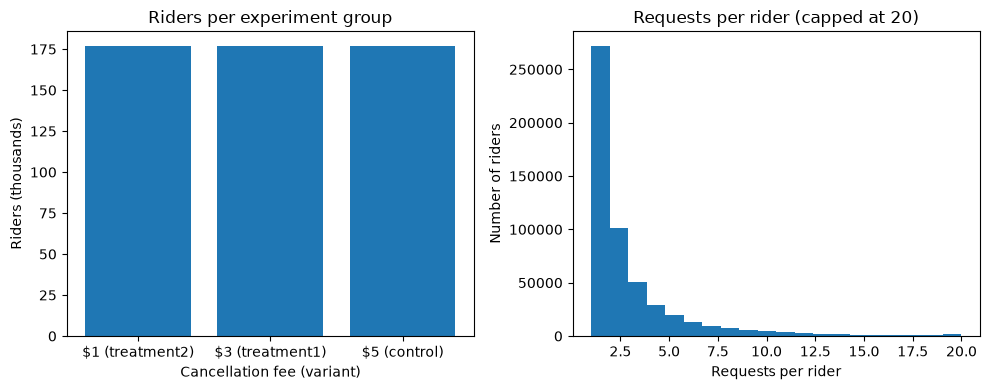

In [34]:
plt.rcParams["text.parse_math"] = False
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
s = summary.sort_values("cancel_penalty")
labels = [f"${f:.0f} ({v})" for f, v in zip(s.cancel_penalty, s.variant)]
ax[0].bar(labels, s.riders / 1000)
ax[0].set(title="Riders per experiment group", xlabel="Cancellation fee (variant)",
          ylabel="Riders (thousands)")
ax[1].hist(per_rider.clip(upper=20), bins=20)
ax[1].set(title="Requests per rider (capped at 20)", xlabel="Requests per rider",
          ylabel="Number of riders")
plt.tight_layout()
fig.savefig(OUT_DIR / "overview.png", dpi=150)
plt.show()

## 10. Data-quality findings

Checks that passed:

- 1,402,312 ride requests from 530,756 riders (Apr 14 to May 26, 2019, Pacific time).
- Three fee groups: \$5 (control), \$3 (treatment1), and \$1 (treatment2). The groups are about equal in size (see the sample ratio check).
- No missing values or duplicate riders in the assignment table.
- No duplicate ride IDs, no duplicate rider/request numbers, and no gaps in request numbers.
- No timestamps out of order.
- The join on `rider_id` matched every request to exactly one assignment, and the row count stayed the same.
- The payment on every canceled request equals the assigned fee.

Issues to review (no decisions made here):

1. The ride type is labeled `standard` in the data but `normal` in the dictionary.
2. 1,775 noncanceled rides have no drop-off time, and 1,751 have no pickup time.
3. 10 post-match ETAs exceed 1 hour, with a maximum of 584,845 seconds.
4. Requests per rider are skewed (99th percentile = 16, maximum = 107).
5. Every assigned rider has at least one request, so riders with no requests may be missing from the export.
6. The data has no cancellation timestamp and no cancellation reason.